In [31]:
# ==================================
# IMPORTS
# ==================================
import torch
import matplotlib.pyplot as plt
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parents[1]

sys.path.insert(
    0,
    str(PROJECT_ROOT)
)


from flow.couette.dataset import CouetteDataset
from core.fno import FNO1d
from torch.utils.data import DataLoader, random_split
import numpy as np



In [32]:

# ==================================
# DEVICE
# ==================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Using:", device)


Using: cpu


In [33]:

# ==================================
# LOAD CHECKPOINT
# ==================================

checkpoint = torch.load(
    str(PROJECT_ROOT) + 
    "/flow/couette/checkpoints/best_fn_100.pt",
    map_location=device
)

print("Checkpoint Loaded...")



FileNotFoundError: [Errno 2] No such file or directory: '/Users/gopal/Python/Hello/Navier/flow/couette/checkpoints/best_fn_100.pt'

In [34]:

# ==================================
# LOAD MODEL
# ==================================

model = FNO1d(
    modes=checkpoint["modes"],
    width=checkpoint["width"],
    in_channels=checkpoint["in_channels"],
    out_channels=checkpoint["out_channels"]
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Model Loaded...")


Model Loaded...


In [35]:

# ==================================
# LOAD DATASET
# ==================================

dataset = CouetteDataset(
    str(PROJECT_ROOT) + 
    "/flow/couette/data/couette_dataset_100.pt"
)

print("Dataset Loaded...")

n_train = int(0.8 * len(dataset))
n_val = len(dataset) - n_train

train_set, val_set = random_split(
    dataset,
    [n_train, n_val]
)

val_loader = DataLoader(
    val_set,
    batch_size=64,
    shuffle=False
)

print(
    f"Validation Samples: {len(val_set)}"
)


Dataset Loaded...
Validation Samples: 2654


In [36]:
def relative_l2(pred, target):

    num = torch.norm(
        pred - target,
        p=2,
        dim=(-2,-1)
    )

    den = torch.norm(
        target,
        p=2,
        dim=(-2,-1)
    )

    return num / (den + 1e-8)

In [37]:
# ==================================
# Full Dataset Evaluation
# ==================================

all_rel_l2 = []
all_mse = []
all_mae = []

best_error = float("inf")
worst_error = 0

best_sample = None
worst_sample = None

sample_counter = 0

with torch.no_grad():

    for batch in val_loader:

        a = batch["a"].to(device)
        u = batch["u"].to(device)

        pred = model(a)

        rel = relative_l2(
            pred,
            u
        )

        mse = (
            (pred-u)**2
        ).mean(
            dim=(-2,-1)
        )

        mae = (
            pred-u
        ).abs().mean(
            dim=(-2,-1)
        )

        for i in range(len(rel)):

            err = rel[i].item()

            all_rel_l2.append(err)
            all_mse.append(
                mse[i].item()
            )

            all_mae.append(
                mae[i].item()
            )

            if err < best_error:

                best_error = err

                best_sample = {
                    "a": a[i].cpu(),
                    "u": u[i].cpu(),
                    "pred": pred[i].cpu(),
                    "err": err
                }

            if err > worst_error:

                worst_error = err

                worst_sample = {
                    "a": a[i].cpu(),
                    "u": u[i].cpu(),
                    "pred": pred[i].cpu(),
                    "err": err
                }

            sample_counter += 1

In [38]:
# ==================================
# Summary Statistics
# ==================================

print(f"Samples       : {sample_counter}")
print(f"Mean Rel L2   : {np.mean(all_rel_l2):.6f}")
print(f"Mean MSE      : {np.mean(all_mse):.6f}")
print(f"Mean MAE      : {np.mean(all_mae):.6f}")
print(f"Best Rel L2   : {best_error:.6f}")
print(f"Worst Rel L2  : {worst_error:.6f}")

Samples       : 2654
Mean Rel L2   : 0.193083
Mean MSE      : 0.037554
Mean MAE      : 0.149951
Best Rel L2   : 0.156595
Worst Rel L2  : 0.369791


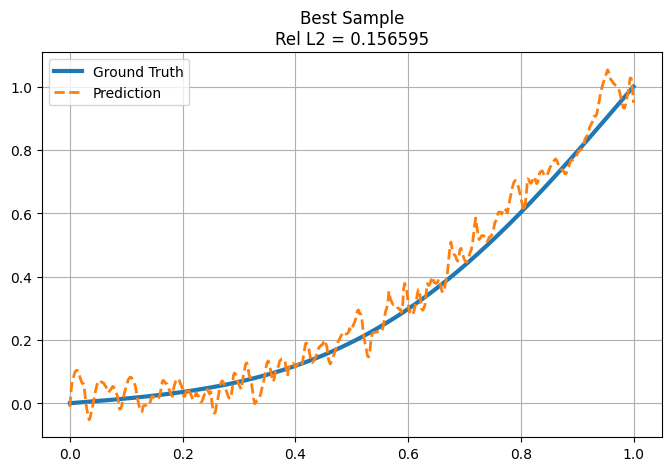

In [39]:
# ==================================
# Best Sample
# ==================================

y = dataset.y

target = (
    best_sample["u"].squeeze()
    * dataset.Y_std
    + dataset.Y_mean
)

pred = (
    best_sample["pred"].squeeze()
    * dataset.Y_std
    + dataset.Y_mean
)
plt.figure(figsize=(8,5))

plt.plot(
    y,
    target,
    label="Ground Truth",
    linewidth=3
)

plt.plot(
    y,
    pred,
    '--',
    label="Prediction",
    linewidth=2
)

plt.title(
    f"Best Sample\nRel L2 = {best_error:.6f}"
)

plt.grid(True)
plt.legend()

plt.show()

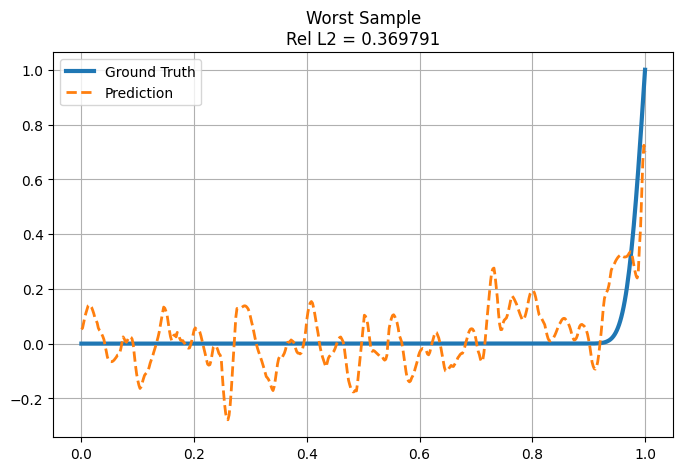

In [40]:
# ==================================
# Worst Sample
# ==================================
target = (
    worst_sample["u"].squeeze()
    * dataset.Y_std
    + dataset.Y_mean
)

pred = (
    worst_sample["pred"].squeeze()
    * dataset.Y_std
    + dataset.Y_mean
)

plt.figure(figsize=(8,5))

plt.plot(
    y,
    target,
    label="Ground Truth",
    linewidth=3
)

plt.plot(
    y,
    pred,
    '--',
    label="Prediction",
    linewidth=2
)

plt.title(
    f"Worst Sample\nRel L2 = {worst_error:.6f}"
)

plt.grid(True)
plt.legend()

plt.show()

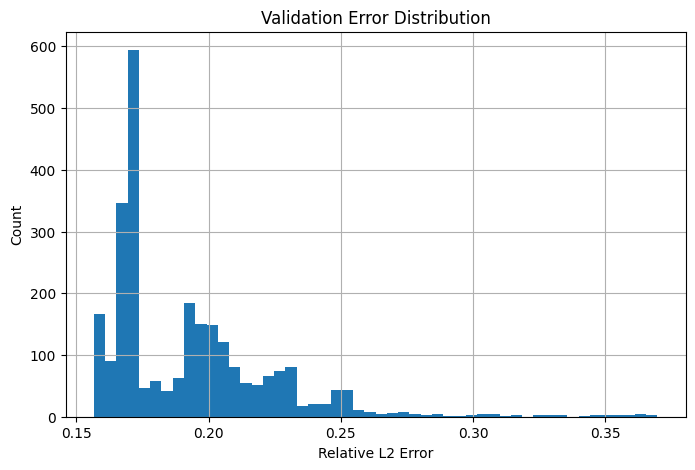

In [41]:
# ==================================
# Val Error Dist
# ==================================
plt.figure(
    figsize=(8,5)
)

plt.hist(
    all_rel_l2,
    bins=50
)

plt.xlabel(
    "Relative L2 Error"
)

plt.ylabel(
    "Count"
)

plt.title(
    "Validation Error Distribution"
)

plt.grid(True)

plt.show()